In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROC = Path("../data/processed")
REP  = Path("../output/reports")
FIG  = Path("../output/figures"); FIG.mkdir(parents=True, exist_ok=True)

fact = pd.read_parquet(PROC / "fact_budidaya.parquet")
print("Fact shape:", fact.shape)
fact.head()

Fact shape: (11916, 13)


,tahun,kabupaten,jenis_budidaya,metrik,nilai,satuan,sumber,source_file,is_missing_year,is_stale,is_suspect_scale,kegiatan,komoditas
0,2020,Pacitan,JARING APUNG,produksi_ton,0.000,TON,jumlah,Jumlah Produksi Perikanan Budidaya Berdasarkan...,False,False,False,None,None
1,2020,Pacitan,KARAMBA,produksi_ton,0.000,TON,jumlah,Jumlah Produksi Perikanan Budidaya Berdasarkan...,False,False,False,None,None
2,2020,Pacitan,KOLAM,produksi_ton,455.776,TON,jumlah,Jumlah Produksi Perikanan Budidaya Berdasarkan...,False,False,False,None,None
3,2020,Pacitan,LAUT,produksi_ton,156.090,TON,jumlah,Jumlah Produksi Perikanan Budidaya Berdasarkan...,False,False,False,None,None
4,2020,Pacitan,MINA PADI,produksi_ton,2.355,TON,jumlah,Jumlah Produksi Perikanan Budidaya Berdasarkan...,False,False,False,None,None


In [32]:
f = fact[fact["tahun"].notna()].copy()
f = f[~f["is_suspect_scale"]]
f = f[~f["is_missing_year"]]

prod_a1 = (f[(f["sumber"]=="jumlah") & (f["metrik"]=="produksi_ton")]
           .groupby(["kabupaten","tahun"])["nilai"].sum(min_count=1).rename("produksi_ton"))
nilai = (f[(f["sumber"]=="bps_nilai") & (f["metrik"]=="nilai_rp")]
         .groupby(["kabupaten","tahun"])["nilai"].sum(min_count=1).div(1e6).rename("nilai_rp_juta"))
rtp = (f[f["metrik"]=="rtp"]
       .groupby(["kabupaten","tahun"])["nilai"].sum(min_count=1).rename("rtp"))
pembudidaya = (f[f["metrik"]=="pembudidaya"]
               .groupby(["kabupaten","tahun"])["nilai"].sum(min_count=1).rename("pembudidaya"))
luas = (f[f["metrik"]=="luas_lahan_ha"]
        .groupby(["kabupaten","tahun"])["nilai"].sum(min_count=1).rename("luas_lahan_ha"))

feat = pd.concat([prod_a1, nilai, rtp, pembudidaya, luas], axis=1).reset_index()

pemb = f[(f["kegiatan"]=="pembesaran") & (f["metrik"]=="produksi_ton")].copy()
base = pemb.groupby(["kabupaten","tahun"])["nilai"].sum().rename("total_pembesaran")
share_df = base.to_frame()
for kom in ["RUMPUT LAUT","UDANG","BANDENG","LELE","NILA","GURAMI","PATIN"]:
    s = (pemb[pemb["komoditas"]==kom]
         .groupby(["kabupaten","tahun"])["nilai"].sum()
         .rename(f"share_{kom.lower().replace(' ','_')}"))
    share_df = share_df.join(s, how="left")
share_df = share_df.fillna(0)
for c in [c for c in share_df.columns if c.startswith("share_")]:
    share_df[c] = share_df[c] / share_df["total_pembesaran"].replace(0, np.nan)
feat = feat.merge(share_df.reset_index(), on=["kabupaten","tahun"], how="left")

feat.to_parquet(PROC / "features_raw.parquet", index=False)
print(feat.shape)
feat.describe().T

(221, 15)


,count,mean,std,min,25%,50%,75%,max
tahun,221.0,2022.420814,1.67856,2020.0,2021.0,2022.0,2024.0,2025.0
produksi_ton,186.0,17204.436048,30650.649633,0.0,832.579,4841.125,16273.69875,160439.075
nilai_rp_juta,76.0,520446.019335,870941.961426,1386.551,35366.390125,134504.22895,444817.1125,4021390.853
rtp,190.0,3357.768421,5413.915162,0.0,822.25,2121.0,3086.5,37497.0
pembudidaya,190.0,4619.826316,6739.471207,200.0,1179.25,2603.0,4192.0,37649.0
luas_lahan_ha,134.0,5390.422015,10658.797314,1.99,175.6525,1378.845,4297.8125,70325.5
total_pembesaran,190.0,54719.532947,185408.600843,60.29,1752.8425,9073.91,28232.4125,1379059.92
share_rumput_laut,190.0,0.027998,0.120545,0.0,0.0,0.0,0.0,0.989599
share_udang,190.0,0.10906,0.180967,0.0,0.0,0.015141,0.124747,0.924777
share_bandeng,190.0,0.06936,0.141762,0.0,0.0,0.0,0.077103,0.807841


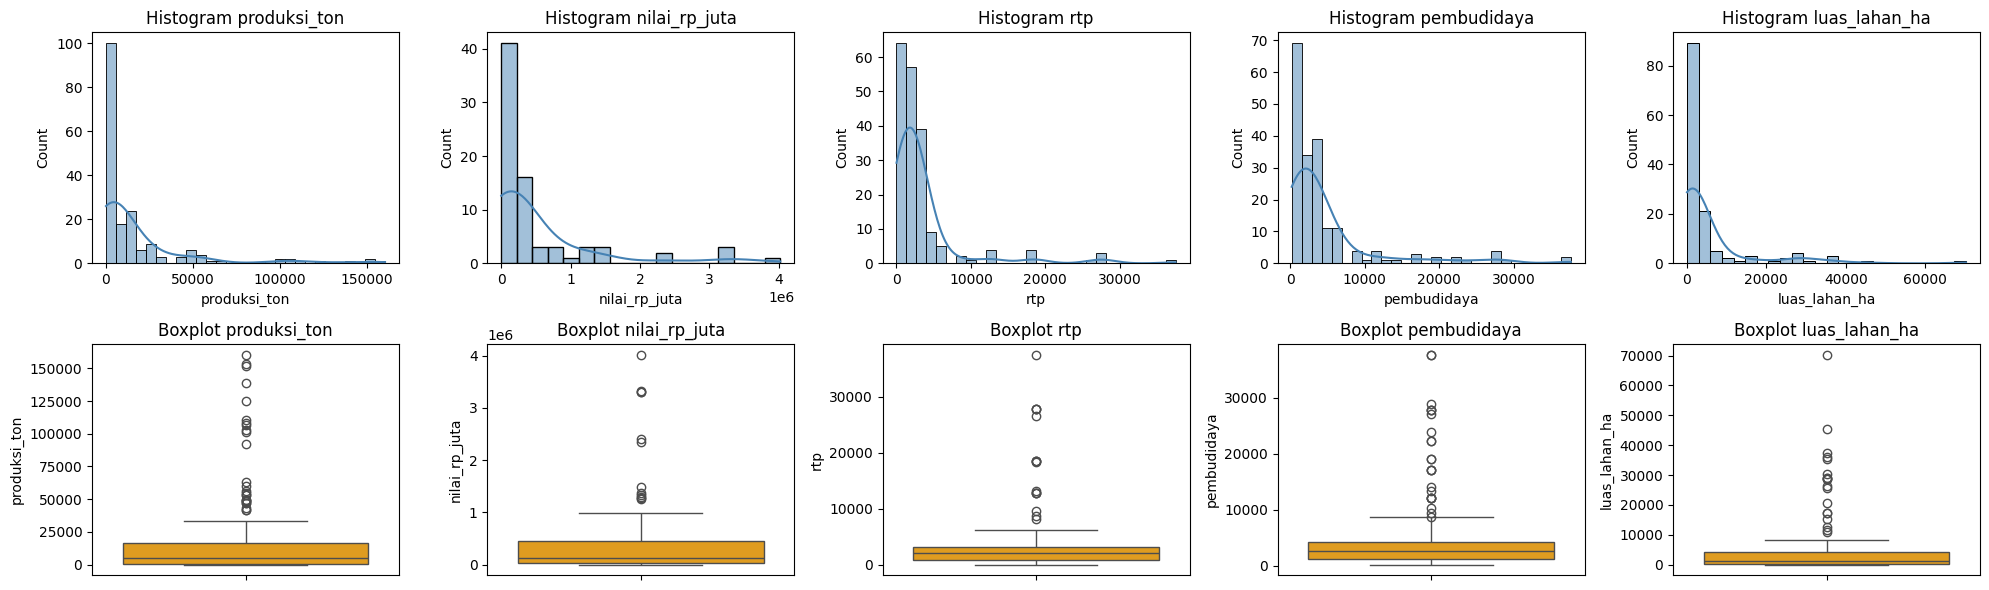

In [33]:
num_cols = ["produksi_ton","nilai_rp_juta","rtp","pembudidaya","luas_lahan_ha"]
fig, axes = plt.subplots(2, len(num_cols), figsize=(4*len(num_cols), 6))
for i, c in enumerate(num_cols):
    sns.histplot(feat[c].dropna(), kde=True, ax=axes[0,i], color="steelblue")
    axes[0,i].set_title(f"Histogram {c}")
    sns.boxplot(y=feat[c].dropna(), ax=axes[1,i], color="orange")
    axes[1,i].set_title(f"Boxplot {c}")
plt.tight_layout(); plt.savefig(FIG/"eda_distribusi_mentah.png", dpi=110); plt.show()

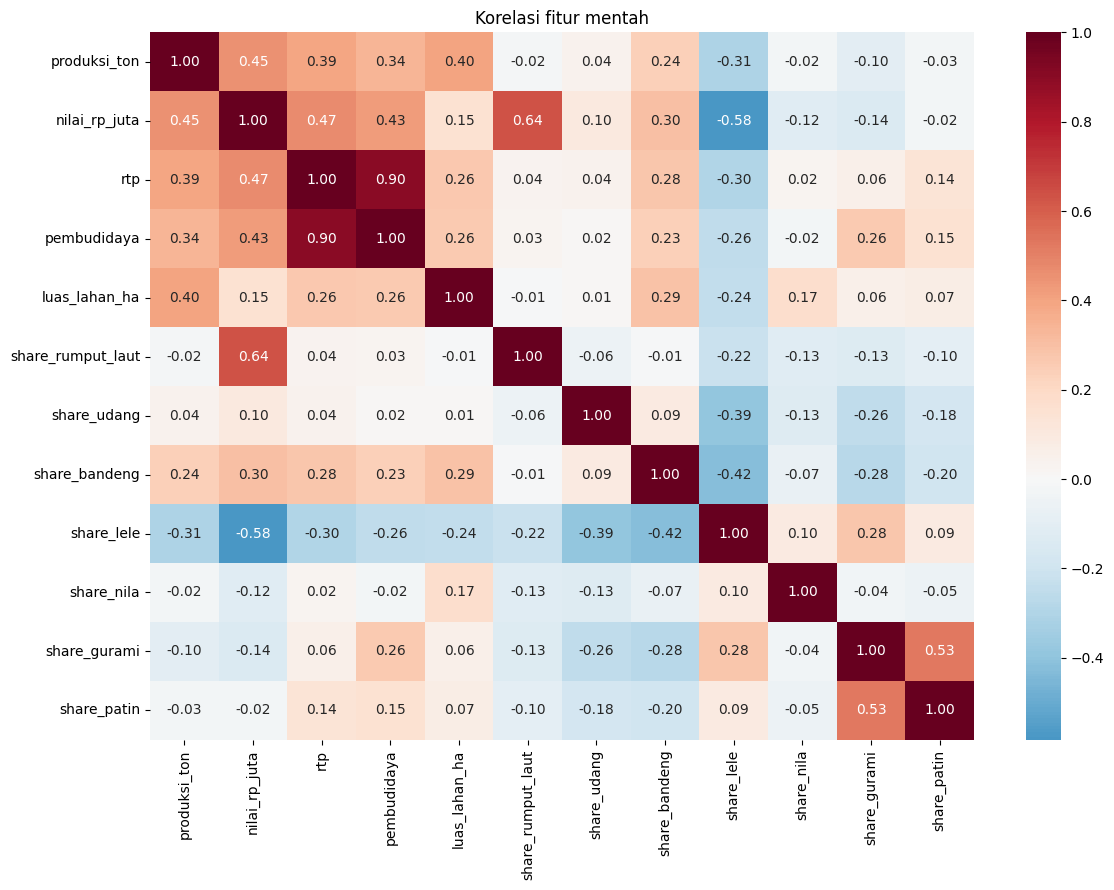

In [34]:
corr_cols = num_cols + [c for c in feat.columns if c.startswith("share_")]
plt.figure(figsize=(12,9))
sns.heatmap(feat[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Korelasi fitur mentah"); plt.tight_layout()
plt.savefig(FIG/"eda_korelasi_mentah.png", dpi=110); plt.show()

In [35]:
def iqr_report(df, cols, k=3.0):
    rows = []
    for c in cols:
        s = df[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - k*iqr, q3 + k*iqr
        n_out = ((s < lo) | (s > hi)).sum()
        rows.append({"fitur": c, "min": s.min(), "max": s.max(),
                     "lower": lo, "upper": hi, "n_outlier": n_out})
    return pd.DataFrame(rows).sort_values("n_outlier", ascending=False)

outlier_report = iqr_report(feat, num_cols)
outlier_report.to_csv(REP/"outlier_report_mentah.csv", index=False)
outlier_report

,fitur,min,max,lower,upper,n_outlier
3,pembudidaya,200.000,37649.000,-7.859000e+03,1.323025e+04,17
4,luas_lahan_ha,1.990,70325.500,-1.219083e+04,1.666429e+04,15
2,rtp,0.000,37497.000,-5.970500e+03,9.879250e+03,13
0,produksi_ton,0.000,160439.075,-4.549078e+04,6.259706e+04,12
1,nilai_rp_juta,1386.551,4021390.853,-1.192986e+06,1.673169e+06,6


In [36]:
feat_clean = feat.copy()
for c in num_cols:
    lo, hi = feat_clean[c].quantile([0.01, 0.99])
    feat_clean[c] = feat_clean[c].clip(lo, hi)
for c in [c for c in feat_clean.columns if c.startswith("share_")]:
    feat_clean[c] = feat_clean[c].clip(0, 1)
feat_clean.to_parquet(PROC/"features_clean.parquet", index=False)
print("Setelah winsorize:"); feat_clean[num_cols].describe().T

Setelah winsorize:


,count,mean,std,min,25%,50%,75%,max
produksi_ton,186.0,17152.860720,30415.306648,0.0000,832.579000,4841.12500,16273.69875,1.518818e+05
nilai_rp_juta,76.0,513526.366682,844439.444400,1432.4105,35366.390125,134504.22895,444817.11250,3.495451e+06
rtp,190.0,3306.668421,5128.266505,0.0000,822.250000,2121.00000,3086.50000,2.778800e+04
pembudidaya,190.0,4537.922842,6372.468776,233.1300,1179.250000,2603.00000,4192.00000,2.979454e+04
luas_lahan_ha,134.0,5164.984975,9529.348791,4.4554,175.652500,1378.84500,4297.81250,4.282855e+04


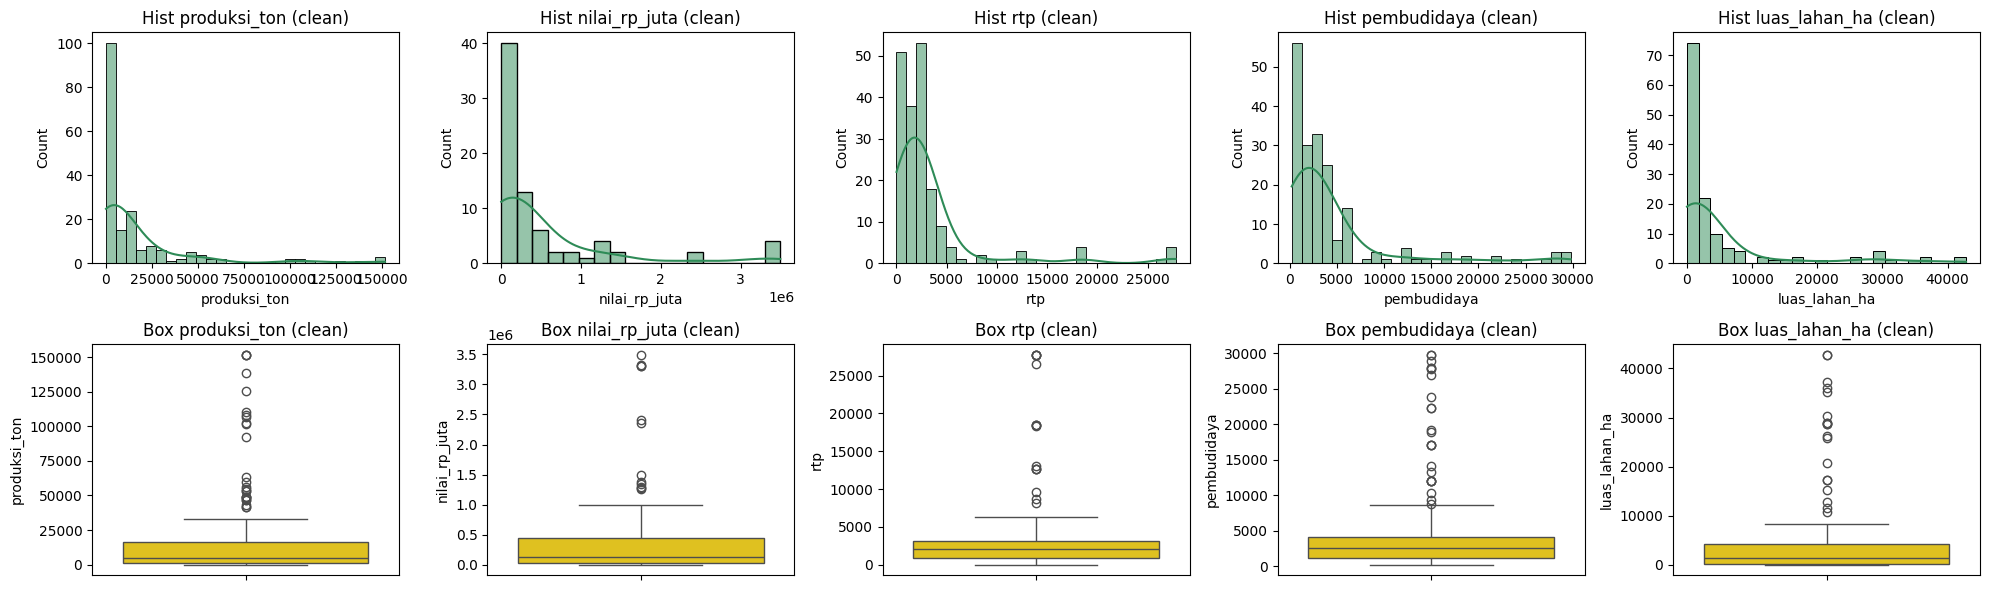

In [37]:
fig, axes = plt.subplots(2, len(num_cols), figsize=(4*len(num_cols), 6))
for i, c in enumerate(num_cols):
    sns.histplot(feat_clean[c].dropna(), kde=True, ax=axes[0,i], color="seagreen")
    axes[0,i].set_title(f"Hist {c} (clean)")
    sns.boxplot(y=feat_clean[c].dropna(), ax=axes[1,i], color="gold")
    axes[1,i].set_title(f"Box {c} (clean)")
plt.tight_layout(); plt.savefig(FIG/"eda_distribusi_clean.png", dpi=110); plt.show()

In [38]:
def tahun_layak_model(df, config):
    """
    Tahun layak untuk clustering/regresi jika:
    - Jumlah kabupaten unik >= coverage_threshold * total kabupaten
    - Jumlah metrik lengkap (non-null >= metric_coverage_min) >= min_metrik_lengkap
    """
    total_kab = df["kabupaten"].nunique()
    metrik_kunci = ["produksi_ton", "nilai_rp_juta", "rtp", "pembudidaya", "luas_lahan_ha"]
    min_metrik = int(config.get("min_metrik_lengkap", 3))

    rows = []
    for th, g in df.groupby("tahun"):
        n_kab = g["kabupaten"].nunique()
        ratio_kab = n_kab / total_kab
        ok_kab = ratio_kab >= config["coverage_threshold"]

        n_metrik_lengkap = sum(
            g[m].notna().mean() >= config["metric_coverage_min"]
            for m in metrik_kunci if m in g.columns
        )
        ok_metrik = n_metrik_lengkap >= min_metrik

        rows.append({
            "tahun": th,
            "n_kab": n_kab,
            "ratio_kab": round(ratio_kab, 3),
            "ok_kab": ok_kab,
            "n_metrik_lengkap": n_metrik_lengkap,
            "n_metrik_total": len([m for m in metrik_kunci if m in g.columns]),
            "ok_metrik": ok_metrik,
            "layak_model": ok_kab and ok_metrik,
        })
    return pd.DataFrame(rows)


# --- baca config ---
_raw = pd.read_csv(REP / "config.csv", index_col=0)["value"].to_dict()

def _to_float(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return v

CONFIG = {
    "coverage_threshold":          _to_float(_raw.get("coverage_threshold", 0.90)),
    "metric_coverage_min":         _to_float(_raw.get("metric_coverage_min", 0.50)),
    "min_metrik_lengkap":          int(float(_raw.get("min_metrik_lengkap", 3))),
    "outlier_mad_k":               _to_float(_raw.get("outlier_mad_k", 5.0)),
    "outlier_iqr_k_fallback":      _to_float(_raw.get("outlier_iqr_k_fallback", 1.5)),
    "label_top_share_min":         _to_float(_raw.get("label_top_share_min", 0.20)),
    "min_samples_regression":      int(float(_raw.get("min_samples_regression", 10))),
    "min_kab_clustering":          int(float(_raw.get("min_kab_clustering", 10))),
    "suspect_scale_produksi_ton":  _to_float(_raw.get("suspect_scale_produksi_ton", 100_000)),
    "suspect_scale_luas_ha":       _to_float(_raw.get("suspect_scale_luas_ha", 100_000)),
}
print(CONFIG)

status_tahun = tahun_layak_model(feat_clean, CONFIG)
status_tahun.to_csv(REP / "status_kelayakan_tahun.csv", index=False)
display(status_tahun)

tahun_layak = status_tahun.loc[status_tahun["layak_model"], "tahun"].tolist()
print("Tahun layak model:", tahun_layak)

feat_model = feat_clean[feat_clean["tahun"].isin(tahun_layak)].copy()
feat_model.to_parquet(PROC / "features_model.parquet", index=False)
print("features_model:", feat_model.shape)

# Simpan juga versi strict (semua metrik lengkap) untuk audit
tahun_strict = status_tahun.loc[
    status_tahun["n_metrik_lengkap"] == status_tahun["n_metrik_total"], "tahun"
].tolist()
feat_model_strict = feat_clean[feat_clean["tahun"].isin(tahun_strict)].copy()
feat_model_strict.to_parquet(PROC / "features_model_strict.parquet", index=False)
print("Tahun strict (semua metrik lengkap):", tahun_strict)
print("features_model_strict:", feat_model_strict.shape)

{'coverage_threshold': 0.9, 'metric_coverage_min': 0.5, 'min_metrik_lengkap': 3, 'outlier_mad_k': 5.0, 'outlier_iqr_k_fallback': 1.5, 'label_top_share_min': 0.2, 'min_samples_regression': 10, 'min_kab_clustering': 10, 'suspect_scale_produksi_ton': 100000.0, 'suspect_scale_luas_ha': 100000.0}


,tahun,n_kab,ratio_kab,ok_kab,n_metrik_lengkap,n_metrik_total,ok_metrik,layak_model
0,2020,38,1.000,True,4,5,True,True
1,2021,38,1.000,True,4,5,True,True
2,2022,38,1.000,True,4,5,True,True
3,2023,38,1.000,True,5,5,True,True
4,2024,38,1.000,True,4,5,True,True
5,2025,31,0.816,False,1,5,False,False


Tahun layak model: [2020, 2021, 2022, 2023, 2024]
features_model: (190, 15)
Tahun strict (semua metrik lengkap): [2023]
features_model_strict: (38, 15)


In [39]:
prod  = fact[(fact["metrik"] == "produksi_ton") & (~fact["is_suspect_scale"])]
luas_ = fact[(fact["metrik"] == "luas_lahan_ha") & (~fact["is_missing_year"]) & (~fact["is_suspect_scale"])]

# R1: produksi ~ luas
r1 = prod.merge(luas_, on=["kabupaten", "tahun", "jenis_budidaya"], suffixes=("_prod", "_luas"))
r1 = r1[["kabupaten", "tahun", "jenis_budidaya", "nilai_prod", "nilai_luas"]].dropna()
r1.columns = ["kabupaten", "tahun", "jenis_budidaya", "y_produksi_ton", "x_luas_ha"]
r1 = r1[(r1["x_luas_ha"] > 0) & (r1["y_produksi_ton"] > 0)]
r1.to_parquet(PROC / "reg_produksi_luas.parquet", index=False)
print("R1", r1.shape)

# R2: produksi ~ RTP
rtp_ = fact[(fact["metrik"] == "rtp") & (~fact["is_stale"])]
r2 = prod.merge(rtp_, on=["kabupaten", "tahun", "jenis_budidaya"], suffixes=("_prod", "_rtp"))
r2 = r2[["kabupaten", "tahun", "jenis_budidaya", "nilai_prod", "nilai_rtp"]].dropna()
r2.columns = ["kabupaten", "tahun", "jenis_budidaya", "y_produksi_ton", "x_rtp"]
r2 = r2[(r2["x_rtp"] > 0) & (r2["y_produksi_ton"] > 0)]
r2.to_parquet(PROC / "reg_produksi_rtp.parquet", index=False)
print("R2", r2.shape)

# R3: nilai ~ volume (per komoditas, pembesaran)
pemb2 = fact[fact["kegiatan"] == "pembesaran"]
v = pemb2[pemb2["metrik"] == "produksi_ton"][["kabupaten", "tahun", "komoditas", "nilai"]].rename(columns={"nilai": "x_volume_ton"})
n = pemb2[pemb2["metrik"] == "nilai_rp_juta"][["kabupaten", "tahun", "komoditas", "nilai"]].rename(columns={"nilai": "y_nilai_rp_juta"})
r3 = v.merge(n, on=["kabupaten", "tahun", "komoditas"]).dropna()
r3 = r3[(r3["x_volume_ton"] > 0) & (r3["y_nilai_rp_juta"] > 0)]
r3.to_parquet(PROC / "reg_nilai_volume.parquet", index=False)
print("R3", r3.shape)

R1 (291, 5)
R2 (245, 5)
R3 (2323, 5)


In [40]:
summary = []
for name, df in [
    ("features_raw", feat),
    ("features_clean", feat_clean),
    ("features_model", feat_model),
    ("features_model_strict", feat_model_strict),
    ("reg_prod_luas", r1),
    ("reg_prod_rtp", r2),
    ("reg_nilai_volume", r3),
]:
    summary.append({
        "dataset": name,
        "n_rows": len(df),
        "n_kab": df["kabupaten"].nunique(),
        "tahun_min": int(df["tahun"].min()) if df["tahun"].notna().any() else None,
        "tahun_max": int(df["tahun"].max()) if df["tahun"].notna().any() else None,
    })
pd.DataFrame(summary).to_csv(REP / "eda_summary.csv", index=False)
pd.DataFrame(summary)

,dataset,n_rows,n_kab,tahun_min,tahun_max
0,features_raw,221,38,2020,2025
1,features_clean,221,38,2020,2025
2,features_model,190,38,2020,2024
3,features_model_strict,38,38,2023,2023
4,reg_prod_luas,291,31,2020,2023
5,reg_prod_rtp,245,31,2020,2024
6,reg_nilai_volume,2323,38,2020,2024
